In [3]:
# %% [CELL 1] --- Install dependencies ---
!pip install -q lightgbm xgboost catboost shap optuna imbalanced-learn scikit-learn
!pip install mapie==0.8.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.1/141.1 kB 1.2 MB/s eta 0:00:00
  Attempting uninstall: mapie
    Found existing installation: MAPIE 1.5.0
    Uninstalling MAPIE-1.5.0:
      Successfully uninstalled MAPIE-1.5.0


In [1]:
# %% [CELL 2] --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, cross_validate
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
    brier_score_loss, confusion_matrix, make_scorer
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE

from scipy.stats import ttest_rel, wilcoxon

import shap
from mapie.classification import MapieClassifier

import optuna

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("/content/model_artifacts", exist_ok=True)
ARTIFACT_DIR = "/content/model_artifacts"

In [3]:
# %% [CELL 3] --- Load data ---
# Upload diabetes_binary_5050split_health_indicators_BRFSS2015.csv to Colab first
# (left sidebar -> Files -> upload), or mount Drive and point to its path.

df = pd.read_csv("diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
print("Shape:", df.shape)
print(df["Diabetes_binary"].value_counts(normalize=True))
df.head()

Shape: (70692, 22)
Diabetes_binary
0.0    0.5
1.0    0.5
Name: proportion, dtype: float64


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [4]:
# %% [CELL 4] --- Feature setup ---
TARGET = "Diabetes_binary"
FEATURES = [c for c in df.columns if c != TARGET]

X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()

# Save feature config for later use in the web app
feature_config = {
    "features": FEATURES,
    "n_features": len(FEATURES),
    "feature_ranges": {
        col: {"min": float(X[col].min()), "max": float(X[col].max())}
        for col in FEATURES
    }
}
with open(f"{ARTIFACT_DIR}/feature_config.json", "w") as f:
    json.dump(feature_config, f, indent=2)

print(f"Using {len(FEATURES)} features:", FEATURES)

Using 21 features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [5]:
# %% [CELL 5] --- Train / test split (held out for final evaluation only) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

joblib.dump(scaler, f"{ARTIFACT_DIR}/scaler.joblib")

['/content/model_artifacts/scaler.joblib']

In [6]:
# %% [CELL 6] --- Repeated Stratified K-Fold model comparison ---
# This replaces a single train/test split comparison with mean +/- std over
# multiple folds/repeats, matching how the base paper (Nugraha & Febrian,
# 2026) reports its results, so your numbers are directly comparable.

def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
        "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        "CatBoost": CatBoostClassifier(verbose=0, random_state=RANDOM_STATE),
    }

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

cv_results = []
fold_level_scores = {}  # store per-fold scores for significance testing later

for name, model in get_models().items():
    print(f"Running CV for {name} ...")
    cv = cross_validate(
        model, X_train_scaled, y_train,
        cv=rskf, scoring=scoring, n_jobs=-1, return_train_score=False
    )
    fold_level_scores[name] = cv  # keep raw fold arrays

    row = {"Model": name}
    for metric in scoring:
        scores = cv[f"test_{metric}"]
        row[f"{metric}_mean"] = scores.mean()
        row[f"{metric}_std"] = scores.std()
    cv_results.append(row)

cv_results_df = pd.DataFrame(cv_results).sort_values("recall_mean", ascending=False)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("\n--- Repeated Stratified 5x5 CV Results (mean ± std) ---")
print(cv_results_df.to_string(index=False))
cv_results_df.to_csv(f"{ARTIFACT_DIR}/cv_results_no_balancing.csv", index=False)

Running CV for Logistic Regression ...
Running CV for Random Forest ...
Running CV for Gradient Boosting ...
Running CV for XGBoost ...
Running CV for LightGBM ...
Running CV for CatBoost ...

--- Repeated Stratified 5x5 CV Results (mean ± std) ---
              Model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  roc_auc_mean  roc_auc_std  average_precision_mean  average_precision_std
           LightGBM         0.7524        0.0033                  0.7524                 0.0033          0.7308         0.0043       0.7992      0.0044   0.7635  0.0029        0.8296       0.0025                  0.8040                 0.0037
           CatBoost         0.7516        0.0028                  0.7516                 0.0028          0.7316         0.0039       0.7951      0.0043   0.7620  0.0024        0.8283       0.0023                  0.8013                 0.0036
  Gradient Boosting   

In [7]:
# %% [CELL 7] --- Repeat CV with SMOTE and class_weight balancing ---
# SMOTE must be applied INSIDE each fold (not before CV) to avoid data leakage.
# We build small pipelines per fold manually since imblearn's Pipeline handles this correctly.

from imblearn.pipeline import Pipeline as ImbPipeline

def get_models_with_balancing():
    models = {}
    # class_weight variants (only where supported natively)
    models["Logistic Regression (class_weight)"] = LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
    models["Random Forest (class_weight)"] = RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
    models["XGBoost (scale_pos_weight)"] = XGBClassifier(
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
        scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]))
    models["LightGBM (class_weight)"] = LGBMClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    models["CatBoost (class_weights)"] = CatBoostClassifier(
        verbose=0, random_state=RANDOM_STATE, auto_class_weights="Balanced")

    # SMOTE variants (wrapped in imblearn Pipeline so it's fold-safe)
    for base_name, base_model in get_models().items():
        models[f"{base_name} (SMOTE)"] = ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("clf", base_model)
        ])
    return models

balanced_results = []
for name, model in get_models_with_balancing().items():
    print(f"Running CV for {name} ...")
    cv = cross_validate(
        model, X_train_scaled, y_train,
        cv=rskf, scoring=scoring, n_jobs=-1, return_train_score=False
    )
    fold_level_scores[name] = cv

    row = {"Model": name}
    for metric in scoring:
        scores = cv[f"test_{metric}"]
        row[f"{metric}_mean"] = scores.mean()
        row[f"{metric}_std"] = scores.std()
    balanced_results.append(row)

balanced_results_df = pd.DataFrame(balanced_results).sort_values("recall_mean", ascending=False)
print("\n--- Balanced Model CV Results (mean ± std) ---")
print(balanced_results_df.to_string(index=False))
balanced_results_df.to_csv(f"{ARTIFACT_DIR}/cv_results_balanced.csv", index=False)

# Combine everything into one master comparison table
all_results_df = pd.concat([cv_results_df, balanced_results_df], ignore_index=True)
all_results_df = all_results_df.sort_values("recall_mean", ascending=False)
all_results_df.to_csv(f"{ARTIFACT_DIR}/cv_results_all.csv", index=False)
print("\n=== TOP 5 MODELS BY RECALL ===")
print(all_results_df[["Model", "accuracy_mean", "roc_auc_mean", "recall_mean", "f1_mean"]].head(5).to_string(index=False))


Running CV for Logistic Regression (class_weight) ...
Running CV for Random Forest (class_weight) ...
Running CV for XGBoost (scale_pos_weight) ...
Running CV for LightGBM (class_weight) ...
Running CV for CatBoost (class_weights) ...
Running CV for Logistic Regression (SMOTE) ...
Running CV for Random Forest (SMOTE) ...
Running CV for Gradient Boosting (SMOTE) ...
Running CV for XGBoost (SMOTE) ...
Running CV for LightGBM (SMOTE) ...
Running CV for CatBoost (SMOTE) ...

--- Balanced Model CV Results (mean ± std) ---
                             Model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  roc_auc_mean  roc_auc_std  average_precision_mean  average_precision_std
                  LightGBM (SMOTE)         0.7524        0.0032                  0.7524                 0.0032          0.7307         0.0041       0.7996      0.0045   0.7636  0.0028        0.8296       0.0026         

In [8]:
# %% [CELL 8] --- Statistical significance test vs base paper's best model ---
# Compare your best model's fold-level scores against your own CatBoost run
# (closest reproduction of the base paper's best model) using a paired test.
# This is what lets you honestly say "statistically significant" or not.

BEST_MODEL_NAME = all_results_df.iloc[0]["Model"]  # auto-picks top model by recall
print(f"Best model selected: {BEST_MODEL_NAME}")

baseline_name = "CatBoost"  # closest match to base paper's best model, no balancing
if baseline_name in fold_level_scores and BEST_MODEL_NAME in fold_level_scores:
    best_recall_folds = fold_level_scores[BEST_MODEL_NAME]["test_recall"]
    baseline_recall_folds = fold_level_scores[baseline_name]["test_recall"]

    t_stat, p_val_t = ttest_rel(best_recall_folds, baseline_recall_folds)
    w_stat, p_val_w = wilcoxon(best_recall_folds, baseline_recall_folds)

    print(f"\nPaired t-test  (Recall, {BEST_MODEL_NAME} vs {baseline_name}): "
          f"t={t_stat:.4f}, p={p_val_t:.4f}")
    print(f"Wilcoxon test  (Recall, {BEST_MODEL_NAME} vs {baseline_name}): "
          f"stat={w_stat:.4f}, p={p_val_w:.4f}")

    if p_val_t < 0.05:
        print(">> Statistically significant improvement (p < 0.05). Safe to claim improvement.")
    else:
        print(">> NOT statistically significant (p >= 0.05). Report as 'comparable performance', "
              "not 'improvement', and lean on your explainability/fairness/uncertainty contributions instead.")
else:
    print("Baseline model not found in fold_level_scores — check naming.")


Best model selected: LightGBM (SMOTE)

Paired t-test  (Recall, LightGBM (SMOTE) vs CatBoost): t=8.3852, p=0.0000
Wilcoxon test  (Recall, LightGBM (SMOTE) vs CatBoost): stat=9.0000, p=0.0000
>> Statistically significant improvement (p < 0.05). Safe to claim improvement.


In [9]:
# %% [CELL 9] --- Hyperparameter tuning (Optuna) for the chosen model family ---
# Tuning LightGBM specifically since it's a strong, fast, tunable baseline.
# Swap in CatBoost/XGBoost the same way if your CV picked a different winner.

def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 15, 150),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
        "verbose": -1,
    }
    model = LGBMClassifier(**params)
    cv3 = RepeatedStratifiedKFold(n_splits=3, n_repeats=1, random_state=RANDOM_STATE)
    scores = cross_validate(model, X_train_scaled, y_train, cv=cv3, scoring="recall", n_jobs=-1)
    return scores["test_score"].mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("Best trial recall:", study.best_value)
print("Best params:", study.best_params)

best_params = study.best_params
best_params.update({"class_weight": "balanced", "random_state": RANDOM_STATE, "n_jobs": -1, "verbose": -1})


[I 2026-09-14 16:15:09,130] A new study created in memory with name: no-name-86775620-75a4-4eca-badc-23dc443b970e


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-09-14 16:15:14,872] Trial 0 finished with value: 0.7963715538956434 and parameters: {'num_leaves': 41, 'max_depth': 3, 'learning_rate': 0.05816309115952625, 'n_estimators': 133, 'min_child_samples': 15, 'subsample': 0.9773072860478488, 'colsample_bytree': 0.6469887277346257, 'reg_alpha': 1.9066169864700218e-07, 'reg_lambda': 1.365947842698091e-07}. Best is trial 0 with value: 0.7963715538956434.
[I 2026-09-14 16:15:40,038] Trial 1 finished with value: 0.7935778964554837 and parameters: {'num_leaves': 134, 'max_depth': 9, 'learning_rate': 0.03968328552539608, 'n_estimators': 350, 'min_child_samples': 50, 'subsample': 0.7840879689331028, 'colsample_bytree': 0.9020900155868609, 'reg_alpha': 2.4021437194029778, 'reg_lambda': 0.08437246459878817}. Best is trial 0 with value: 0.7963715538956434.
[I 2026-09-14 16:16:12,152] Trial 2 finished with value: 0.7965130891604256 and parameters: {'num_leaves': 109, 'max_depth': 9, 'learning_rate': 0.014656003529412953, 'n_estimators': 543, 'mi


--- Final Tuned Model — Held-out Test Set Performance ---
Accuracy:          0.7542
Balanced Accuracy: 0.7542
Precision:         0.7324
Recall:            0.8012
F1-Score:          0.7653
ROC-AUC:           0.8308
PR-AUC:            0.8042
MCC:               0.5107
Brier Score:       0.1665


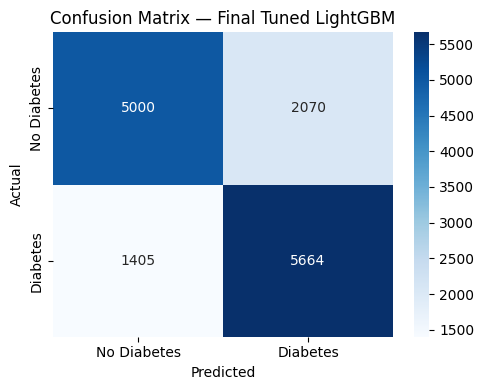

In [10]:
# %% [CELL 10] --- Train final tuned model on full training set ---
final_model = LGBMClassifier(**best_params)
final_model.fit(X_train_scaled, y_train)

y_pred = final_model.predict(X_test_scaled)
y_proba = final_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Final Tuned Model — Held-out Test Set Performance ---")
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Precision:         {precision_score(y_test, y_pred):.4f}")
print(f"Recall:            {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:          {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC:            {average_precision_score(y_test, y_proba):.4f}")
print(f"MCC:               {matthews_corrcoef(y_test, y_pred):.4f}")
print(f"Brier Score:       {brier_score_loss(y_test, y_proba):.4f}")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.title("Confusion Matrix — Final Tuned LightGBM")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig(f"{ARTIFACT_DIR}/confusion_matrix.png", dpi=150)
plt.show()


In [11]:
# %% [CELL 11] --- Threshold tuning (optimize for recall/F1 instead of default 0.5) ---
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_thresh_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_thresh_idx]

print(f"\nDefault threshold (0.5) F1: {f1_score(y_test, y_pred):.4f}")
print(f"Optimal threshold: {best_threshold:.4f}  ->  F1: {f1_scores[best_thresh_idx]:.4f}")

y_pred_tuned = (y_proba >= best_threshold).astype(int)
print(f"Recall @ optimal threshold:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"Precision @ optimal threshold: {precision_score(y_test, y_pred_tuned):.4f}")

with open(f"{ARTIFACT_DIR}/optimal_threshold.json", "w") as f:
    json.dump({"threshold": float(best_threshold)}, f)



Default threshold (0.5) F1: 0.7653
Optimal threshold: 0.3723  ->  F1: 0.7773
Recall @ optimal threshold:    0.8932
Precision @ optimal threshold: 0.6880



Brier Score before calibration: 0.1665
Brier Score after calibration:  0.1664


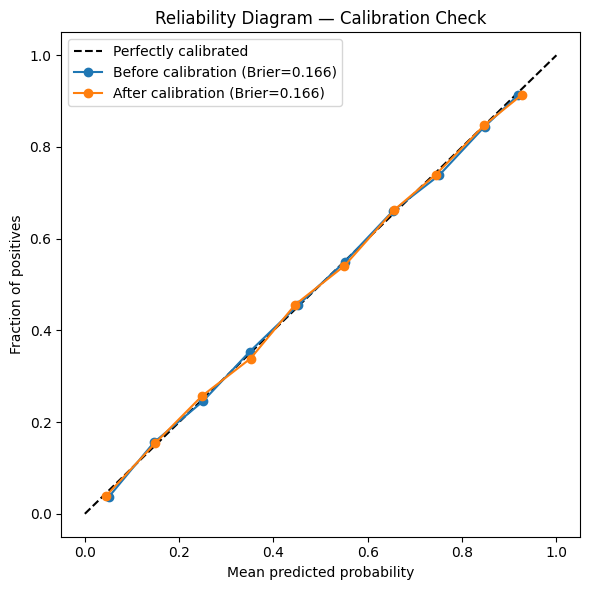

In [12]:
# %% [CELL 12] --- Probability calibration + reliability diagram ---
calibrated_model = CalibratedClassifierCV(final_model, method="isotonic", cv=5)
calibrated_model.fit(X_train_scaled, y_train)

y_proba_calibrated = calibrated_model.predict_proba(X_test_scaled)[:, 1]

brier_before = brier_score_loss(y_test, y_proba)
brier_after = brier_score_loss(y_test, y_proba_calibrated)
print(f"\nBrier Score before calibration: {brier_before:.4f}")
print(f"Brier Score after calibration:  {brier_after:.4f}")

frac_pos_before, mean_pred_before = calibration_curve(y_test, y_proba, n_bins=10)
frac_pos_after, mean_pred_after = calibration_curve(y_test, y_proba_calibrated, n_bins=10)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.plot(mean_pred_before, frac_pos_before, "o-", label=f"Before calibration (Brier={brier_before:.3f})")
plt.plot(mean_pred_after, frac_pos_after, "o-", label=f"After calibration (Brier={brier_after:.3f})")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Reliability Diagram — Calibration Check")
plt.legend()
plt.tight_layout()
plt.savefig(f"{ARTIFACT_DIR}/reliability_diagram.png", dpi=150)
plt.show()

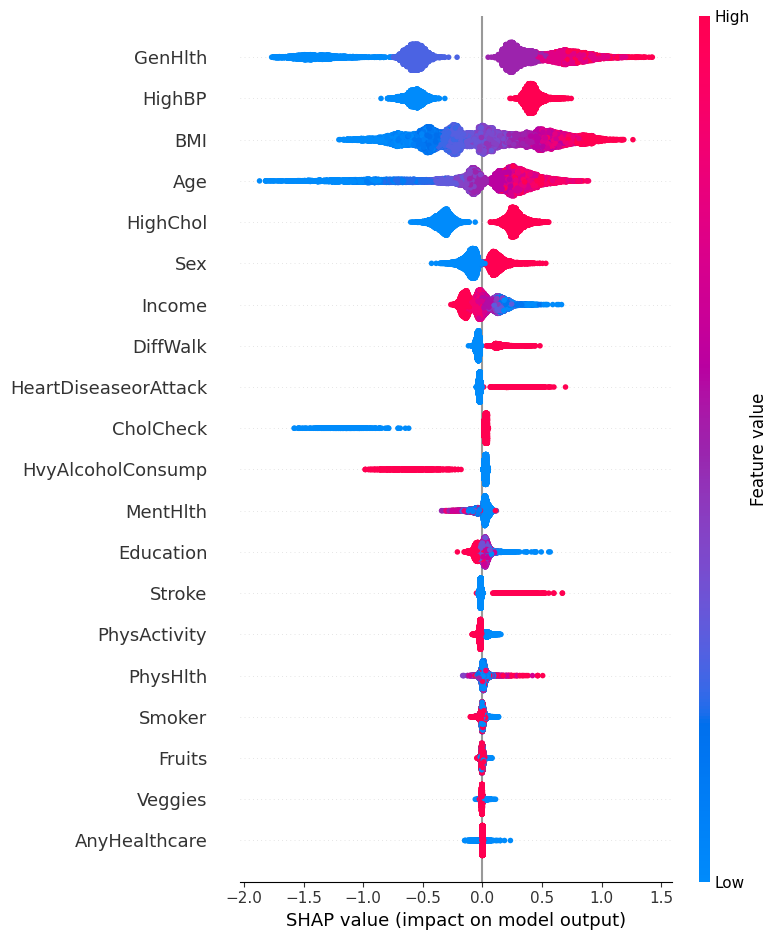


Sample 0 — Predicted probability: 0.897
    feature  shap_value
        BMI      0.7511
    GenHlth      0.6555
     HighBP      0.3942
   HighChol      0.2258
        Age      0.1922
   DiffWalk      0.1225
NoDocbcCost     -0.1040
     Income      0.0857

Sample 1 — Predicted probability: 0.787
             feature  shap_value
              HighBP      0.3622
                 Age      0.2590
             GenHlth      0.1958
            HighChol      0.1775
HeartDiseaseorAttack      0.1770
            DiffWalk      0.1486
              Income      0.1283
                 Sex     -0.1024

Sample 2 — Predicted probability: 0.426
 feature  shap_value
     BMI     -1.1577
  HighBP      0.4038
HighChol      0.2723
 GenHlth      0.2128
     Age      0.1618
     Sex     -0.1516
  Income      0.1389
DiffWalk     -0.0572


['/content/model_artifacts/shap_explainer.joblib']

In [13]:
# %% [CELL 13] --- SHAP explainability ---
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_scaled)

# Global feature importance
plt.figure()
shap.summary_plot(shap_values, X_test_scaled, show=False)
plt.tight_layout()
plt.savefig(f"{ARTIFACT_DIR}/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# Per-instance explanation example (first 3 test samples)
for i in range(3):
    contributions = pd.DataFrame({
        "feature": FEATURES,
        "shap_value": shap_values[i] if not isinstance(shap_values, list) else shap_values[1][i]
    }).sort_values("shap_value", key=abs, ascending=False)
    print(f"\nSample {i} — Predicted probability: {y_proba[i]:.3f}")
    print(contributions.head(8).to_string(index=False))

joblib.dump(explainer, f"{ARTIFACT_DIR}/shap_explainer.joblib")

In [14]:
# %% [CELL 14] --- Conformal prediction with MAPIE (uncertainty quantification) ---
mapie_model = MapieClassifier(estimator=final_model, cv="prefit", method="score")
# MAPIE needs a calibration set — reuse part of training data not used for final fit,
# or split off a small calibration slice. Simplest fold-safe approach: re-split.

X_fit, X_calib, y_fit, y_calib = train_test_split(
    X_train_scaled, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

final_model_for_mapie = LGBMClassifier(**best_params)
final_model_for_mapie.fit(X_fit, y_fit)

mapie_model = MapieClassifier(estimator=final_model_for_mapie, cv="prefit", method="score")
mapie_model.fit(X_calib, y_calib)

alpha = 0.1  # 90% confidence
y_pred_mapie, y_set_mapie = mapie_model.predict(X_test_scaled, alpha=alpha)

# Coverage check: how often does the true label fall inside the predicted set?
coverage = np.mean([y_set_mapie[i, y_test.iloc[i], 0] for i in range(len(y_test))])
print(f"\nMAPIE 90% prediction set empirical coverage: {coverage:.4f} (target ~0.90)")

joblib.dump(mapie_model, f"{ARTIFACT_DIR}/mapie_model.joblib")


MAPIE 90% prediction set empirical coverage: 0.8991 (target ~0.90)


['/content/model_artifacts/mapie_model.joblib']

In [15]:
# %% [CELL 15] --- Fairness audit across subgroups ---
# Uses the ORIGINAL (unscaled) test features so subgroup labels are human-readable.
fairness_df = X_test.copy()
fairness_df["y_true"] = y_test.values
fairness_df["y_pred"] = y_pred
fairness_df["y_proba"] = y_proba

def bucket_age(age_code):
    # BRFSS Age is already bucketed 1-13; group into broader bands for readability
    if age_code <= 3: return "18-34"
    elif age_code <= 6: return "35-49"
    elif age_code <= 9: return "50-64"
    else: return "65+"

def bucket_income(income_code):
    if income_code <= 3: return "Low income"
    elif income_code <= 6: return "Middle income"
    else: return "High income"

fairness_df["AgeGroup"] = fairness_df["Age"].apply(bucket_age)
fairness_df["IncomeGroup"] = fairness_df["Income"].apply(bucket_income)
fairness_df["SexGroup"] = fairness_df["Sex"].map({0: "Female", 1: "Male"})

def compute_group_metrics(data, group_col):
    rows = []
    for group_val, group_data in data.groupby(group_col):
        if group_data["y_true"].nunique() < 2:
            continue  # skip groups with only one class present
        rows.append({
            "Group": group_val,
            "N": len(group_data),
            "Accuracy": accuracy_score(group_data["y_true"], group_data["y_pred"]),
            "Recall": recall_score(group_data["y_true"], group_data["y_pred"]),
            "F1": f1_score(group_data["y_true"], group_data["y_pred"]),
            "ROC_AUC": roc_auc_score(group_data["y_true"], group_data["y_proba"]),
        })
    return pd.DataFrame(rows)

age_fairness = compute_group_metrics(fairness_df, "AgeGroup")
income_fairness = compute_group_metrics(fairness_df, "IncomeGroup")
sex_fairness = compute_group_metrics(fairness_df, "SexGroup")

print("\n--- Fairness: by Age Group ---")
print(age_fairness.to_string(index=False))
print("\n--- Fairness: by Income Group ---")
print(income_fairness.to_string(index=False))
print("\n--- Fairness: by Sex ---")
print(sex_fairness.to_string(index=False))

overall_recall = recall_score(y_test, y_pred)

def flag_disparities(group_df, overall, threshold=0.05):
    group_df = group_df.copy()
    group_df["Recall_Gap"] = group_df["Recall"] - overall
    group_df["Flag"] = group_df["Recall_Gap"].apply(
        lambda g: "UNDERPERFORMING" if g < -threshold else "OK")
    return group_df

age_fairness = flag_disparities(age_fairness, overall_recall)
income_fairness = flag_disparities(income_fairness, overall_recall)
sex_fairness = flag_disparities(sex_fairness, overall_recall)

age_fairness.to_csv(f"{ARTIFACT_DIR}/fairness_age.csv", index=False)
income_fairness.to_csv(f"{ARTIFACT_DIR}/fairness_income.csv", index=False)
sex_fairness.to_csv(f"{ARTIFACT_DIR}/fairness_sex.csv", index=False)

print("\n--- Flagged Disparities (Recall gap > 5 pts below overall) ---")
print(age_fairness[["Group", "Recall", "Recall_Gap", "Flag"]].to_string(index=False))
print(income_fairness[["Group", "Recall", "Recall_Gap", "Flag"]].to_string(index=False))
print(sex_fairness[["Group", "Recall", "Recall_Gap", "Flag"]].to_string(index=False))


--- Fairness: by Age Group ---
Group    N  Accuracy  Recall     F1  ROC_AUC
18-34  911    0.9001  0.3400 0.4277   0.8451
35-49 2159    0.7777  0.5938 0.6279   0.8416
50-64 5113    0.7542  0.7924 0.7674   0.8268
  65+ 5956    0.7235  0.8586 0.7929   0.7675

--- Fairness: by Income Group ---
        Group    N  Accuracy  Recall     F1  ROC_AUC
  High income 6347    0.7681  0.7003 0.6977   0.8444
   Low income 2757    0.7559  0.8952 0.8304   0.7739
Middle income 5035    0.7358  0.8269 0.7770   0.8008

--- Fairness: by Sex ---
 Group    N  Accuracy  Recall     F1  ROC_AUC
Female 7675    0.7620  0.7945 0.7629   0.8413
  Male 6464    0.7450  0.8086 0.7678   0.8171

--- Flagged Disparities (Recall gap > 5 pts below overall) ---
Group  Recall  Recall_Gap            Flag
18-34  0.3400     -0.4612 UNDERPERFORMING
35-49  0.5938     -0.2074 UNDERPERFORMING
50-64  0.7924     -0.0088              OK
  65+  0.8586      0.0574              OK
        Group  Recall  Recall_Gap            Flag
  High i

In [16]:
# %% [CELL 16] --- Population-level insight tables (for the web app's Insights page) ---
population_insights = {
    "by_age_group": fairness_df.groupby("AgeGroup")["y_proba"].mean().round(4).to_dict(),
    "by_income_group": fairness_df.groupby("IncomeGroup")["y_proba"].mean().round(4).to_dict(),
    "by_sex": fairness_df.groupby("SexGroup")["y_proba"].mean().round(4).to_dict(),
    "by_bmi_category": None,  # filled below
}

def bucket_bmi(bmi):
    if bmi < 18.5: return "Underweight"
    elif bmi < 25: return "Normal"
    elif bmi < 30: return "Overweight"
    else: return "Obese"

fairness_df["BMICategory"] = fairness_df["BMI"].apply(bucket_bmi)
population_insights["by_bmi_category"] = fairness_df.groupby("BMICategory")["y_proba"].mean().round(4).to_dict()

with open(f"{ARTIFACT_DIR}/population_insights.json", "w") as f:
    json.dump(population_insights, f, indent=2)

print("\n--- Average Predicted Risk by Subgroup ---")
for key, val in population_insights.items():
    print(f"\n{key}:")
    for k, v in val.items():
        print(f"  {k}: {v:.4f}")



--- Average Predicted Risk by Subgroup ---

by_age_group:
  18-34: 0.1396
  35-49: 0.3249
  50-64: 0.5100
  65+: 0.6168

by_income_group:
  High income: 0.3935
  Low income: 0.6610
  Middle income: 0.5542

by_sex:
  Female: 0.4842
  Male: 0.5251

by_bmi_category:
  Normal: 0.2774
  Obese: 0.6547
  Overweight: 0.4448
  Underweight: 0.2634


In [17]:
# %% [CELL 17] --- Save all final artifacts ---
joblib.dump(final_model, f"{ARTIFACT_DIR}/model_lightgbm_final.joblib")
joblib.dump(calibrated_model, f"{ARTIFACT_DIR}/model_lightgbm_calibrated.joblib")
joblib.dump(scaler, f"{ARTIFACT_DIR}/scaler.joblib")

metadata = {
    "model_name": "LightGBM",
    "balancing_strategy": "class_weight (tuned) — compare against SMOTE in cv_results_all.csv",
    "best_hyperparameters": best_params,
    "optimal_threshold": float(best_threshold),
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred)),
        "recall": float(recall_score(y_test, y_pred)),
        "f1": float(f1_score(y_test, y_pred)),
        "roc_auc": float(roc_auc_score(y_test, y_proba)),
        "brier_score_calibrated": float(brier_after),
        "mapie_90pct_coverage": float(coverage),
    },
    "features": FEATURES,
}
with open(f"{ARTIFACT_DIR}/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\n=== ALL ARTIFACTS SAVED TO /content/model_artifacts ===")
for fname in sorted(os.listdir(ARTIFACT_DIR)):
    print(" -", fname)

print("\nDownload the whole folder as a zip if needed:")
print("  !zip -r model_artifacts.zip /content/model_artifacts")



=== ALL ARTIFACTS SAVED TO /content/model_artifacts ===
 - confusion_matrix.png
 - cv_results_all.csv
 - cv_results_balanced.csv
 - cv_results_no_balancing.csv
 - fairness_age.csv
 - fairness_income.csv
 - fairness_sex.csv
 - feature_config.json
 - mapie_model.joblib
 - model_lightgbm_calibrated.joblib
 - model_lightgbm_final.joblib
 - model_metadata.json
 - optimal_threshold.json
 - population_insights.json
 - reliability_diagram.png
 - scaler.joblib
 - shap_explainer.joblib
 - shap_summary.png

Download the whole folder as a zip if needed:
  !zip -r model_artifacts.zip /content/model_artifacts
